<a href="https://colab.research.google.com/github/AHANIK33/Malicious-Prompt-Detection-Research-code/blob/main/GRU_MAlicious_Prompt_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import re
import time
import random
import threading
import tempfile
import gc
import copy

import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn as nn

from collections import Counter
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


In [ ]:
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# CPU or GPU automatically
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


Device: cuda


In [ ]:
CSV_PATH = "/content/MPDD.csv"
TEXT_COL = "Prompt"
LABEL_COL = "isMalicious"

MAX_VOCAB_SIZE = 20000
MAX_LENGTH = 160
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 1
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 0.001

In [ ]:
df = pd.read_csv(CSV_PATH)

df = df[[TEXT_COL, LABEL_COL]].dropna().copy()
df[TEXT_COL] = df[TEXT_COL].astype(str)

# Convert labels to 0 and 1 if necessary
if not set(df[LABEL_COL].unique()).issubset({0, 1}):
    raise ValueError(
        "Labels must be encoded as 0 and 1. "
        "Encode your target column before training."
    )

df[LABEL_COL] = df[LABEL_COL].astype(int)

print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df[LABEL_COL].value_counts())

X = df[TEXT_COL].tolist()
y = df[LABEL_COL].tolist()


Dataset shape: (39234, 2)

Class distribution:
isMalicious
1    19617
0    19617
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.125,
    random_state=SEED,
    stratify=y_train
)

print("\nTrain samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))


Train samples: 27463
Validation samples: 3924
Test samples: 7847


In [ ]:
def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

counter = Counter()

for text in X_train:
    counter.update(tokenize(text))

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in counter.most_common(MAX_VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

print("\nVocabulary size:", len(vocab))


def encode_text(text):
    tokens = tokenize(text)

    token_ids = [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens
    ]

    token_ids = token_ids[:MAX_LENGTH]

    # Padding
    token_ids += [vocab["<PAD>"]] * (
        MAX_LENGTH - len(token_ids)
    )

    return token_ids



Vocabulary size: 20000


In [ ]:
class PromptDataset(Dataset):

    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        input_ids = encode_text(self.texts[idx])
        label = self.labels[idx]

        return (
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(label, dtype=torch.long)
        )


train_dataset = PromptDataset(X_train, y_train)
val_dataset = PromptDataset(X_val, y_val)
test_dataset = PromptDataset(X_test, y_test)

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


In [ ]:
class GRUClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers=1,
        num_classes=2
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.0 if num_layers == 1 else 0.2,
            bidirectional=False
        )

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids):

        embedded = self.embedding(input_ids)

        # hidden: [num_layers, batch_size, hidden_dim]
        _, hidden = self.gru(embedded)

        last_hidden = hidden[-1]

        output = self.dropout(last_hidden)
        logits = self.fc(output)

        return logits


model = GRUClassifier(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS
).to(device)

print("\nModel architecture:")
print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Model architecture:
GRUClassifier(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (gru): GRU(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)
Total parameters: 2,659,330
Trainable parameters: 2,659,330


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

In [ ]:
process = psutil.Process(os.getpid())

peak_ram_mb = 0.0
monitoring = False


def monitor_ram():
    global peak_ram_mb

    while monitoring:
        try:
            ram_mb = process.memory_info().rss / (1024 ** 2)
            peak_ram_mb = max(peak_ram_mb, ram_mb)
        except psutil.Error:
            pass

        time.sleep(0.02)


In [ ]:
best_val_f1 = -1.0
best_state = None
best_epoch = 0

history = []

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats(device)

peak_ram_mb = process.memory_info().rss / (1024 ** 2)
monitoring = True

ram_thread = threading.Thread(
    target=monitor_ram,
    daemon=True
)
ram_thread.start()

training_start = time.perf_counter()

for epoch in range(EPOCHS):

    # ---------------- TRAIN ----------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for input_ids, labels in train_loader:

        input_ids = input_ids.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(input_ids)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * labels.size(0)

        predictions = logits.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # ---------------- VALIDATION ----------------
    model.eval()

    val_loss = 0.0
    val_true = []
    val_pred = []

    with torch.no_grad():

        for input_ids, labels in val_loader:

            input_ids = input_ids.to(device)
            labels = labels.to(device)

            logits = model(input_ids)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            val_loss += loss.item() * labels.size(0)

            val_true.extend(labels.cpu().tolist())
            val_pred.extend(predictions.cpu().tolist())

    val_loss /= len(val_dataset)

    val_acc = accuracy_score(val_true, val_pred)

    val_f1 = f1_score(
        val_true,
        val_pred,
        zero_division=0
    )

    history.append({
        "Epoch": epoch + 1,
        "Train Loss": train_loss,
        "Train Accuracy": train_acc,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_acc,
        "Validation F1": val_f1
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )


    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch + 1

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }


if device.type == "cuda":
    torch.cuda.synchronize(device)

training_time = time.perf_counter() - training_start

monitoring = False
ram_thread.join(timeout=1)

if device.type == "cuda":
    peak_gpu_memory_mb = (
        torch.cuda.max_memory_allocated(device)
        / (1024 ** 2)
    )
else:
    peak_gpu_memory_mb = None


if best_state is not None:
    model.load_state_dict(best_state)

model.to(device)

print("\nBest epoch:", best_epoch)
print(f"Total training time: {training_time:.4f} seconds")

Epoch 1/10 | Train Loss: 0.5497 | Train Acc: 0.6836 | Val Loss: 0.5050 | Val Acc: 0.7278 | Val F1: 0.6320
Epoch 2/10 | Train Loss: 0.3028 | Train Acc: 0.8633 | Val Loss: 0.1467 | Val Acc: 0.9554 | Val F1: 0.9537
Epoch 3/10 | Train Loss: 0.1396 | Train Acc: 0.9580 | Val Loss: 0.1364 | Val Acc: 0.9587 | Val F1: 0.9579
Epoch 4/10 | Train Loss: 0.1164 | Train Acc: 0.9649 | Val Loss: 0.1151 | Val Acc: 0.9636 | Val F1: 0.9628
Epoch 5/10 | Train Loss: 0.0875 | Train Acc: 0.9730 | Val Loss: 0.1085 | Val Acc: 0.9656 | Val F1: 0.9652
Epoch 6/10 | Train Loss: 0.0629 | Train Acc: 0.9813 | Val Loss: 0.1149 | Val Acc: 0.9641 | Val F1: 0.9631
Epoch 7/10 | Train Loss: 0.0426 | Train Acc: 0.9866 | Val Loss: 0.1520 | Val Acc: 0.9633 | Val F1: 0.9628
Epoch 8/10 | Train Loss: 0.0274 | Train Acc: 0.9916 | Val Loss: 0.1767 | Val Acc: 0.9613 | Val F1: 0.9603
Epoch 9/10 | Train Loss: 0.0208 | Train Acc: 0.9936 | Val Loss: 0.1680 | Val Acc: 0.9618 | Val F1: 0.9613
Epoch 10/10 | Train Loss: 0.0143 | Train Acc: 

In [ ]:
model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for input_ids, labels in test_loader:

        input_ids = input_ids.to(device)

        logits = model(input_ids)
        predictions = logits.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

print("\n========== TEST RESULTS ==========")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    digits=4,
    zero_division=0
))


========== TEST RESULTS ==========
Accuracy : 96.60%
Precision: 0.9751
Recall   : 0.9564
F1-score : 0.9656

Classification Report:
              precision    recall  f1-score   support

           0     0.9572    0.9755    0.9663      3924
           1     0.9751    0.9564    0.9656      3923

    accuracy                         0.9660      7847
   macro avg     0.9661    0.9660    0.9660      7847
weighted avg     0.9661    0.9660    0.9660      7847



In [ ]:
model.eval()

# Warm-up before timing
warmup_batch = next(iter(test_loader))[0].to(device)

with torch.no_grad():
    for _ in range(10):
        _ = model(warmup_batch)

if device.type == "cuda":
    torch.cuda.synchronize(device)

inference_start = time.perf_counter()

total_inference_samples = 0

with torch.no_grad():

    for input_ids, labels in test_loader:

        input_ids = input_ids.to(device)

        _ = model(input_ids)

        total_inference_samples += input_ids.size(0)

        if device.type == "cuda":
            torch.cuda.synchronize(device)

inference_total_time = (
    time.perf_counter() - inference_start
)

inference_time_per_sample_ms = (
    inference_total_time
    / total_inference_samples
) * 1000

inference_time_per_batch_ms = (
    inference_total_time / len(test_loader)
) * 1000

print("\n========== INFERENCE METRICS ==========")

print(
    f"Total inference time: "
    f"{inference_total_time:.6f} seconds"
)

print(
    f"Average inference time per sample: "
    f"{inference_time_per_sample_ms:.4f} ms"
)

print(
    f"Average inference time per batch: "
    f"{inference_time_per_batch_ms:.4f} ms"
)



========== INFERENCE METRICS ==========
Total inference time: 1.513747 seconds
Average inference time per sample: 0.1929 ms
Average inference time per batch: 6.1534 ms


In [ ]:
with tempfile.NamedTemporaryFile(
    suffix=".pth",
    delete=False
) as temp_file:
    model_path = temp_file.name

torch.save(model.state_dict(), model_path)

model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

print("\n========== MODEL SIZE ==========")
print(f"Model size: {model_size_mb:.4f} MB")

os.remove(model_path)


========== MODEL SIZE ==========
Model size: 10.1473 MB


In [ ]:
print("\n========== PEAK MEMORY ==========")
print(f"Peak CPU RAM during training: {peak_ram_mb:.2f} MB")

if peak_gpu_memory_mb is not None:
    print(
        f"Peak GPU allocated memory: "
        f"{peak_gpu_memory_mb:.2f} MB"
    )
else:
    print("GPU memory: Not applicable (CPU training)")



========== PEAK MEMORY ==========
Peak CPU RAM during training: 1477.69 MB
Peak GPU allocated memory: 103.02 MB


In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "vocab": vocab,
    "max_length": MAX_LENGTH,
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "num_layers": NUM_LAYERS
}, "/content/gru_malicious_prompt_model.pth")

print("\nModel saved successfully.")


Model saved successfully.


In [ ]:
results = pd.DataFrame({
    "Metric": [
        "Test Accuracy (%)",
        "Precision",
        "Recall",
        "F1-score",
        "Training Time (seconds)",
        "Inference Time per Sample (ms)",
        "Inference Time per Batch (ms)",
        "Model Size (MB)",
        "Peak CPU RAM (MB)",
        "Peak GPU Memory (MB)"
    ],
    "Value": [
        round(accuracy * 100, 2),
        round(precision, 4),
        round(recall, 4),
        round(f1, 4),
        round(training_time, 4),
        round(inference_time_per_sample_ms, 4),
        round(inference_time_per_batch_ms, 4),
        round(model_size_mb, 4),
        round(peak_ram_mb, 2),
        round(peak_gpu_memory_mb, 2)
        if peak_gpu_memory_mb is not None else "N/A"
    ]
})
print("\n========== FINAL RESULTS TABLE ==========")
print(results.to_string(index=False))

results.to_csv(
    "/content/gru_experiment_results.csv",
    index=False
)

print("\nResults saved to /content/gru_experiment_results.csv")



========== FINAL RESULTS TABLE ==========
                        Metric     Value
             Test Accuracy (%)   96.6000
                     Precision    0.9751
                        Recall    0.9564
                      F1-score    0.9656
       Training Time (seconds)   48.1966
Inference Time per Sample (ms)    0.1929
 Inference Time per Batch (ms)    6.1534
               Model Size (MB)   10.1473
             Peak CPU RAM (MB) 1477.6900
          Peak GPU Memory (MB)  103.0200

Results saved to /content/gru_experiment_results.csv


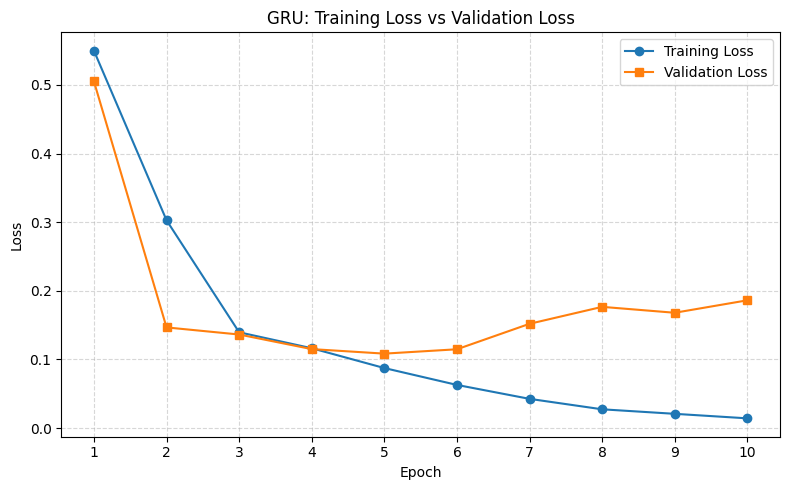

In [ ]:

import matplotlib.pyplot as plt


train_losses = [item["Train Loss"] for item in history]
val_losses = [item["Validation Loss"] for item in history]

epochs = range(1, len(history) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GRU: Training Loss vs Validation Loss")

plt.xticks(list(epochs))
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
